# Image Classification Project: Animals-10
- **Name:** Rashifa Ashri Nurrahim

This project is written in English since I want to make it as my portfolio and push it to GitHub.

## Import All Packages/Libraries

In [1]:
import importlib
import os
import sys
import types

import kagglehub
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import tensorflow as tf
from PIL import Image
from sklearn.metrics import classification_report, confusion_matrix
from sklearn.model_selection import train_test_split
from tensorflow.keras import Sequential, layers
from tensorflow.keras.applications import MobileNetV2
from tensorflow.keras.callbacks import (Callback, EarlyStopping,
                                        ModelCheckpoint, ReduceLROnPlateau)

print("TensorFlow:", tf.__version__)

/Library/Frameworks/Python.framework/Versions/3.13/lib/python3.13/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


TensorFlow: 2.21.0


In [2]:
# tensorflowjs imports two optional packages (tensorflow_decision_forests and jax) that this
# project does not use and that are not available for every Python version.
# If they are missing, register temporary empty modules so tensorflowjs can be imported.
stub_modules = []
for name in ["tensorflow_decision_forests", "jax", "jax.experimental", "jax.experimental.jax2tf"]:
    try:
        importlib.import_module(name)
    except ImportError:
        module = types.ModuleType(name)
        sys.modules[name] = module
        stub_modules.append(name)
        if "." in name:
            parent, child = name.rsplit(".", 1)
            setattr(sys.modules[parent], child, module)

import tensorflowjs as tfjs

for name in stub_modules:
    sys.modules.pop(name, None)

print("TensorFlow.js converter:", tfjs.__version__)

TensorFlow.js converter: 4.22.0


/Users/user/Image_Classification/.venv/lib/python3.13/site-packages/tensorflow_hub/__init__.py:61: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  from pkg_resources import parse_version


## Data Preparation

### Data Loading
The Animals-10 dataset is downloaded from Kaggle using `kagglehub`. The class folders in the original
dataset are named in Italian, so they are translated to English to make the labels easier to read.

In [3]:
dataset_path = kagglehub.dataset_download("alessiocorrado99/animals10")
DATA_DIR = os.path.join(dataset_path, "raw-img")

TRANSLATE = {
    "cane": "dog", "cavallo": "horse", "elefante": "elephant", "farfalla": "butterfly",
    "gallina": "chicken", "gatto": "cat", "mucca": "cow", "pecora": "sheep",
    "ragno": "spider", "scoiattolo": "squirrel",
}

print("Dataset location:", DATA_DIR)
for folder in sorted(os.listdir(DATA_DIR)):
    count = len(os.listdir(os.path.join(DATA_DIR, folder)))
    print(f"{folder} ({TRANSLATE[folder]}): {count} images")

Dataset location: /Users/user/.cache/kagglehub/datasets/alessiocorrado99/animals10/versions/2/raw-img
cane (dog): 4863 images
cavallo (horse): 2623 images
elefante (elephant): 1446 images
farfalla (butterfly): 2112 images
gallina (chicken): 3098 images
gatto (cat): 1668 images
mucca (cow): 1866 images
pecora (sheep): 1820 images
ragno (spider): 4821 images
scoiattolo (squirrel): 1862 images


### Data Exploration
Check the number of images and the variety of resolutions in each class.

In [4]:
def print_images_resolution(directory):
    """Print the number of images per class and the variety of image resolutions in the dataset."""
    unique_sizes = set()
    total_images = 0

    for subdir in sorted(os.listdir(directory)):
        subdir_path = os.path.join(directory, subdir)
        image_files = os.listdir(subdir_path)
        class_sizes = set()

        for img_file in image_files:
            with Image.open(os.path.join(subdir_path, img_file)) as img:
                class_sizes.add(img.size)

        print(f"{subdir} ({TRANSLATE[subdir]}): {len(image_files)} images, "
              f"{len(class_sizes)} unique resolutions, e.g. {sorted(class_sizes)[:3]}")
        total_images += len(image_files)
        unique_sizes |= class_sizes

    print(f"\nTotal images             : {total_images}")
    print(f"Total unique resolutions : {len(unique_sizes)}")


print_images_resolution(DATA_DIR)

cane (dog): 4863 images, 320 unique resolutions, e.g. [(109, 300), (137, 300), (142, 300)]


cavallo (horse): 2623 images, 312 unique resolutions, e.g. [(60, 57), (120, 104), (144, 300)]


elefante (elephant): 1446 images, 284 unique resolutions, e.g. [(189, 300), (193, 220), (193, 300)]


farfalla (butterfly): 2112 images, 371 unique resolutions, e.g. [(65, 64), (102, 111), (144, 300)]


gallina (chicken): 3098 images, 315 unique resolutions, e.g. [(82, 96), (138, 300), (150, 150)]


gatto (cat): 1668 images, 404 unique resolutions, e.g. [(107, 160), (112, 168), (118, 120)]


mucca (cow): 1866 images, 240 unique resolutions, e.g. [(120, 90), (150, 180), (152, 108)]


pecora (sheep): 1820 images, 336 unique resolutions, e.g. [(107, 160), (147, 210), (153, 187)]


ragno (spider): 4821 images, 556 unique resolutions, e.g. [(88, 300), (117, 177), (120, 80)]


scoiattolo (squirrel): 1862 images, 279 unique resolutions, e.g. [(127, 300), (137, 119), (141, 300)]

Total images             : 26179
Total unique resolutions : 1002


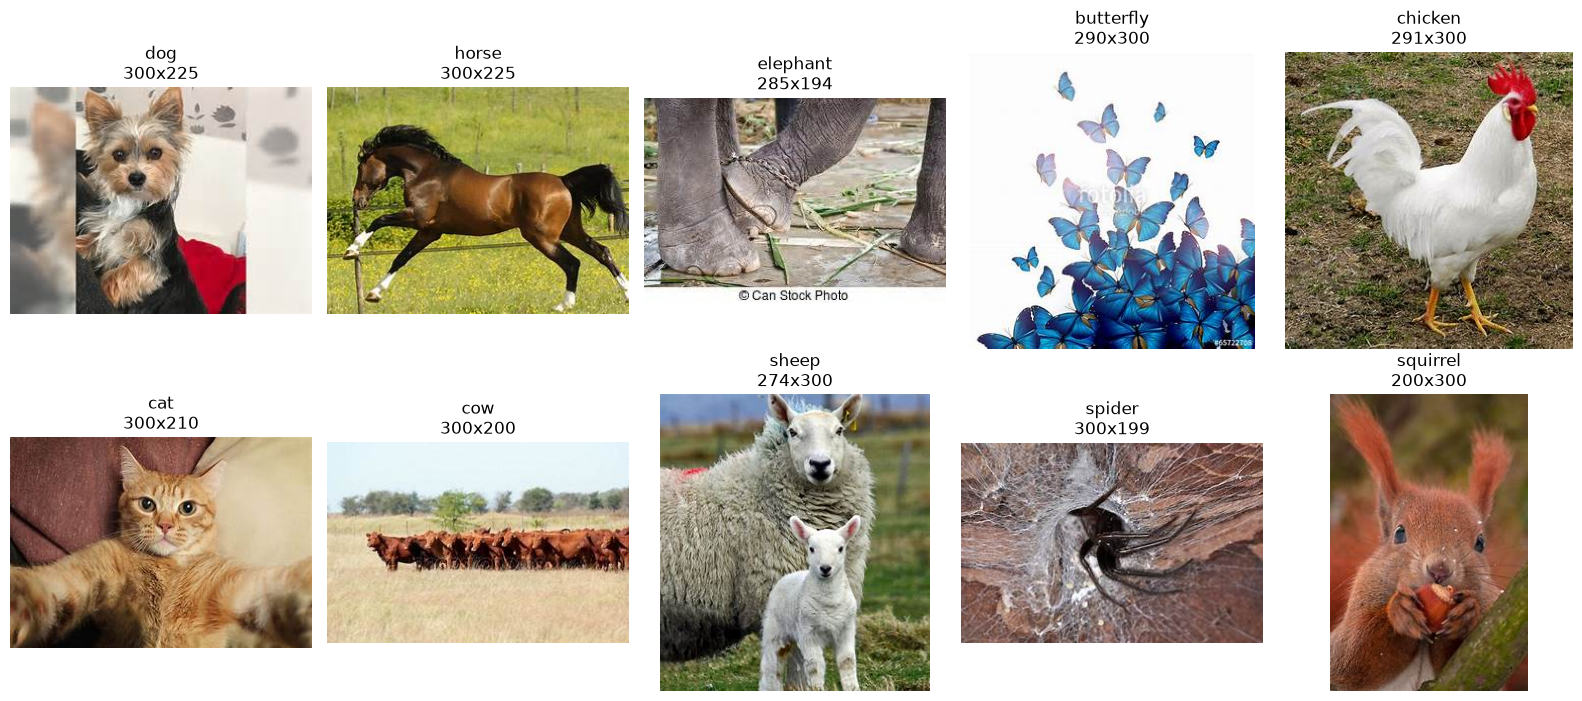

In [5]:
# One original sample image from each class, with its resolution
fig, axes = plt.subplots(2, 5, figsize=(16, 7))
for ax, folder in zip(axes.flat, sorted(os.listdir(DATA_DIR))):
    file_name = sorted(os.listdir(os.path.join(DATA_DIR, folder)))[0]
    with Image.open(os.path.join(DATA_DIR, folder, file_name)) as img:
        ax.imshow(img.convert("RGB"))
        ax.set_title(f"{TRANSLATE[folder]}\n{img.size[0]}x{img.size[1]}")
    ax.axis("off")
plt.tight_layout()
plt.show()

### Data Preprocessing

#### Split Dataset
All image paths and their labels are collected into a DataFrame, then split into
**80% train, 10% validation, and 10% test** using a *stratified* split so the class proportions stay
the same in all three sets.

In [6]:
SEED = 42  # fixed seed so the random split and training are reproducible
np.random.seed(SEED)
tf.random.set_seed(SEED)

records = []
for folder in sorted(os.listdir(DATA_DIR)):
    for file_name in os.listdir(os.path.join(DATA_DIR, folder)):
        records.append({"path": os.path.join(DATA_DIR, folder, file_name), "label": TRANSLATE[folder]})

df = pd.DataFrame(records)
CLASS_NAMES = sorted(df["label"].unique())
NUM_CLASSES = len(CLASS_NAMES)
df["label_id"] = df["label"].map({name: i for i, name in enumerate(CLASS_NAMES)})

print("Total images:", len(df))
print("Classes     :", CLASS_NAMES)
df.sample(5, random_state=SEED)

Total images: 26179
Classes     : ['butterfly', 'cat', 'chicken', 'cow', 'dog', 'elephant', 'horse', 'sheep', 'spider', 'squirrel']


,path,label,label_id
1968,/Users/user/.cache/kagglehub/datase...,dog,4
17679,/Users/user/.cache/kagglehub/datase...,sheep,7
5923,/Users/user/.cache/kagglehub/datase...,horse,6
1087,/Users/user/.cache/kagglehub/datase...,dog,4
7172,/Users/user/.cache/kagglehub/datase...,horse,6


#### Data Cleaning
Animals-10 was collected from Google Images, so it contains some images that are not real animals
(tattoos, clip art, toys, food, and unrelated photos). These images are listed in `excluded_images.txt`
and removed from the DataFrame so the model only learns from real animal photos.

In [7]:
with open("excluded_images.txt") as f:
    excluded = set(f.read().splitlines())

# Each entry in excluded_images.txt is "<class folder>/<file name>"
relative_path = df["path"].map(lambda p: "/".join(p.split(os.sep)[-2:]))
df = df[~relative_path.isin(excluded)].reset_index(drop=True)

print("Excluded images :", len(excluded))
print("Remaining images:", len(df))
df["label"].value_counts()

Excluded images : 583
Remaining images: 25596


label
dog          4849
spider       4801
chicken      3071
horse        2618
squirrel     1861
cow          1856
sheep        1816
cat          1666
butterfly    1617
elephant     1441
Name: count, dtype: int64

In [8]:
train_df, temp_df = train_test_split(df, test_size=0.2, stratify=df["label_id"], random_state=SEED)
val_df, test_df = train_test_split(temp_df, test_size=0.5, stratify=temp_df["label_id"], random_state=SEED)

split_summary = pd.DataFrame({
    "train": train_df["label"].value_counts(),
    "validation": val_df["label"].value_counts(),
    "test": test_df["label"].value_counts(),
}).sort_index()
split_summary.loc["TOTAL"] = split_summary.sum()
split_summary

,train,validation,test
label,,,
butterfly,1293,162,162
cat,1333,166,167
chicken,2457,307,307
cow,1485,186,185
dog,3879,485,485
elephant,1153,144,144
horse,2094,262,262
sheep,1453,181,182
spider,3840,481,480


#### Data Pipeline and Augmentation
- Each image is read, converted to 3 channels (RGB), and resized to 224x224.
- **Augmentation is applied to the training data only** (random flip, rotation, zoom, and contrast).
  Validation and test data are not augmented so the evaluation stays consistent.
- Pixel normalization is done inside the model (a `Rescaling` layer), so the pipeline keeps pixel values in 0-255.

In [9]:
IMG_SIZE = (224, 224)
BATCH_SIZE = 32


def load_image(path, label):
    """Read an image file, decode it to RGB, and resize it to IMG_SIZE."""
    image = tf.io.read_file(path)
    image = tf.io.decode_image(image, channels=3, expand_animations=False)
    image = tf.image.resize(image, IMG_SIZE)
    return image, label


data_augmentation = Sequential([
    layers.RandomFlip("horizontal"),
    layers.RandomRotation(0.05),
    layers.RandomZoom(0.1),
    layers.RandomContrast(0.1),
], name="data_augmentation")


def make_dataset(frame, training=False):
    """Build a batched tf.data pipeline; shuffling and augmentation only when training=True."""
    dataset = tf.data.Dataset.from_tensor_slices((frame["path"].values, frame["label_id"].values))
    if training:
        dataset = dataset.shuffle(len(frame), seed=SEED)
    dataset = dataset.map(load_image, num_parallel_calls=tf.data.AUTOTUNE).batch(BATCH_SIZE)
    if training:
        dataset = dataset.map(lambda x, y: (data_augmentation(x, training=True), y),
                              num_parallel_calls=tf.data.AUTOTUNE)
    return dataset.prefetch(tf.data.AUTOTUNE)


train_ds = make_dataset(train_df, training=True)
train_eval_ds = make_dataset(train_df)  # training data without augmentation, for the final evaluation
val_ds = make_dataset(val_df)
test_ds = make_dataset(test_df)

print("Train batches     :", len(train_ds))
print("Validation batches:", len(val_ds))
print("Test batches      :", len(test_ds))

Train batches     : 640
Validation batches: 80
Test batches      : 80


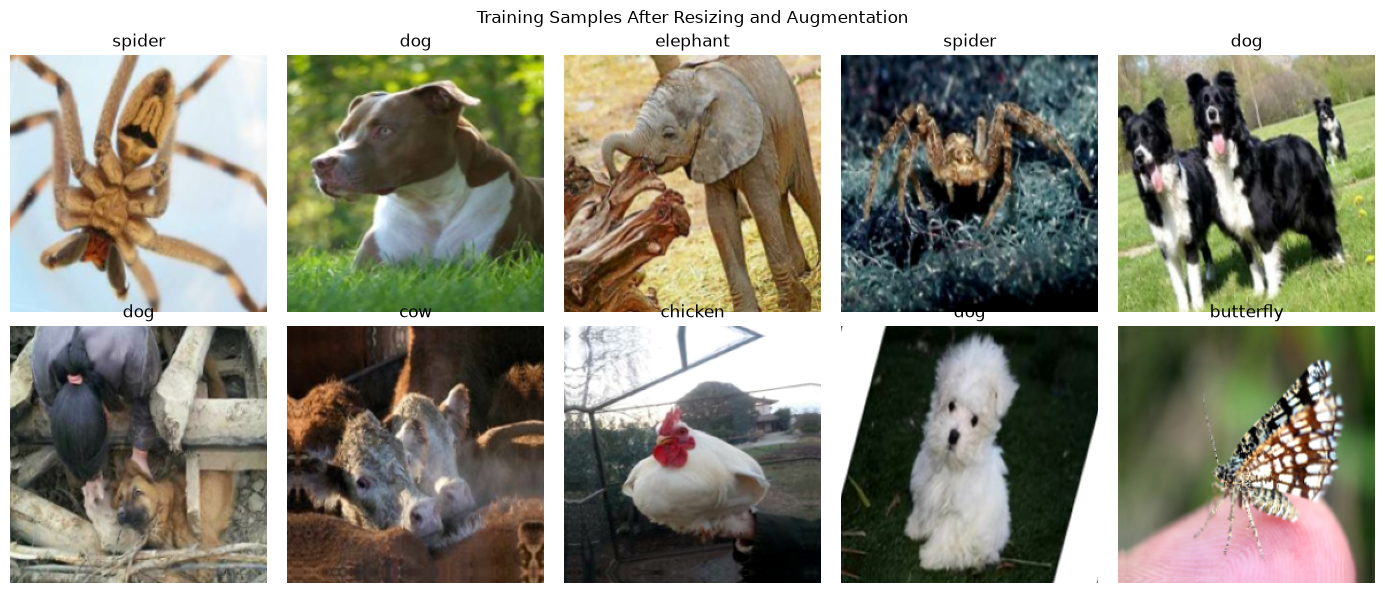

In [10]:
# Sample training images after resizing and augmentation
images, labels = next(iter(train_ds))
plt.figure(figsize=(14, 6))
for i in range(10):
    plt.subplot(2, 5, i + 1)
    plt.imshow(images[i].numpy().clip(0, 255).astype("uint8"))
    plt.title(CLASS_NAMES[labels[i]])
    plt.axis("off")
plt.suptitle("Training Samples After Resizing and Augmentation")
plt.tight_layout()
plt.show()

## Modelling
The model is built with **`Sequential`** and consists of:
1. `Rescaling` to normalize pixel values to the range [-1, 1].
2. **MobileNetV2** (pre-trained on ImageNet, frozen) as the feature extractor.
3. Additional **`Conv2D`** and **`MaxPooling2D`** layers to learn features specific to this dataset.
4. `GlobalAveragePooling2D`, `Dense`, and `Dropout` as the classifier with a 10-class output.

In [11]:
base_model = MobileNetV2(input_shape=IMG_SIZE + (3,), include_top=False, weights="imagenet")
base_model.trainable = False

model = Sequential([
    layers.Input(shape=IMG_SIZE + (3,)),
    layers.Rescaling(1.0 / 127.5, offset=-1),
    base_model,
    layers.Conv2D(128, (3, 3), padding="same", activation="relu"),
    layers.MaxPooling2D((2, 2)),
    layers.GlobalAveragePooling2D(),
    layers.Dropout(0.3),
    layers.Dense(128, activation="relu"),
    layers.Dropout(0.3),
    layers.Dense(NUM_CLASSES, activation="softmax"),
], name="animals10_classifier")

model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-3),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"],
)
model.summary()

Model: "animals10_classifier"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ rescaling (Rescaling)           │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_1.00_224            │ (None, 7, 7, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 7, 7, 128)      │     1,474,688 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 3, 3, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 128)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │        16,512 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 3,750,474 (14.31 MB)

 Trainable params: 1,492,490 (5.69 MB)

 Non-trainable params: 2,257,984 (8.61 MB)

### Callbacks
- **`TargetAccuracyCallback`** (custom): stops training once both training and validation accuracy pass the target.
- **`EarlyStopping`**: stops training if `val_loss` stops improving and restores the best weights.
- **`ModelCheckpoint`**: saves the best model based on `val_accuracy`.
- **`ReduceLROnPlateau`**: lowers the learning rate when `val_loss` plateaus.

In [12]:
class TargetAccuracyCallback(Callback):
    """Stop training once training and validation accuracy both reach the target."""

    def __init__(self, target=0.96):
        super().__init__()
        self.target = target

    def on_epoch_end(self, epoch, logs=None):
        logs = logs or {}
        if logs.get("accuracy", 0) >= self.target and logs.get("val_accuracy", 0) >= self.target:
            print(f"\nTraining and validation accuracy reached {self.target:.0%}, stopping training.")
            self.model.stop_training = True


callbacks = [
    TargetAccuracyCallback(target=0.96),
    EarlyStopping(monitor="val_loss", patience=4, restore_best_weights=True, verbose=1),
    ModelCheckpoint("best_model.keras", monitor="val_accuracy", save_best_only=True, verbose=1),
    ReduceLROnPlateau(monitor="val_loss", factor=0.3, patience=2, min_lr=1e-6, verbose=1),
]

### Training

In [13]:
EPOCHS = 10

history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=EPOCHS,
    callbacks=callbacks,
    verbose=2,
)

Epoch 1/10


/Library/Frameworks/Python.framework/Versions/3.13/lib/python3.13/site-packages/keras/src/trainers/epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(



Epoch 1: val_accuracy improved from None to 0.96016, saving model to best_model.keras



Epoch 1: finished saving model to best_model.keras


640/640 - 709s - 1s/step - accuracy: 0.8735 - loss: 0.4582 - val_accuracy: 0.9602 - val_loss: 0.1529 - learning_rate: 0.0010


...

640/640 - 546s - 854ms/step - accuracy: 0.9506 - loss: 0.1686 - val_accuracy: 0.9645 - val_loss: 0.1255 - learning_rate: 0.0010


Epoch 7/10



Training and validation accuracy reached 96%, stopping training.

Epoch 7: val_accuracy did not improve from 0.96758


640/640 - 625s - 977ms/step - accuracy: 0.9634 - loss: 0.1221 - val_accuracy: 0.9660 - val_loss: 0.1152 - learning_rate: 3.0000e-04


Restoring model weights from the end of the best epoch: 4.


## Evaluation and Visualization

### Accuracy and Loss Plots

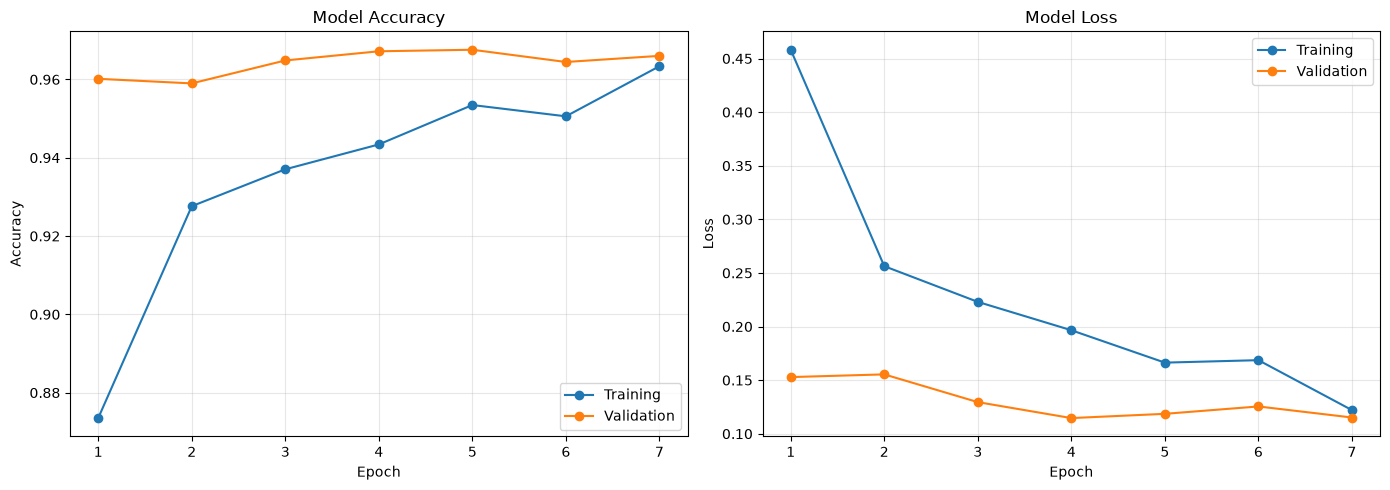

In [14]:
epochs_range = range(1, len(history.history["accuracy"]) + 1)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
axes[0].plot(epochs_range, history.history["accuracy"], marker="o", label="Training")
axes[0].plot(epochs_range, history.history["val_accuracy"], marker="o", label="Validation")
axes[0].set_title("Model Accuracy")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Accuracy")
axes[0].legend()
axes[0].grid(alpha=0.3)

axes[1].plot(epochs_range, history.history["loss"], marker="o", label="Training")
axes[1].plot(epochs_range, history.history["val_loss"], marker="o", label="Validation")
axes[1].set_title("Model Loss")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Loss")
axes[1].legend()
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()

### Accuracy on the Train, Validation, and Test Sets
The best model (saved by `ModelCheckpoint`) is loaded again and evaluated on all three sets.
The training set is evaluated **without augmentation** so it is comparable to the validation and test sets.

In [15]:
model = tf.keras.models.load_model("best_model.keras")

train_loss, train_acc = model.evaluate(train_eval_ds, verbose=0)
val_loss, val_acc = model.evaluate(val_ds, verbose=0)
test_loss, test_acc = model.evaluate(test_ds, verbose=0)

print(f"Training set   -> accuracy: {train_acc:.4f} | loss: {train_loss:.4f}")
print(f"Validation set -> accuracy: {val_acc:.4f} | loss: {val_loss:.4f}")
print(f"Testing set    -> accuracy: {test_acc:.4f} | loss: {test_loss:.4f}")

Training set   -> accuracy: 0.9763 | loss: 0.0835
Validation set -> accuracy: 0.9676 | loss: 0.1186
Testing set    -> accuracy: 0.9598 | loss: 0.1532


### Classification Report and Confusion Matrix (Test Set)

In [16]:
y_true = test_df["label_id"].values
y_pred = np.argmax(model.predict(test_ds, verbose=0), axis=1)

print(classification_report(y_true, y_pred, target_names=CLASS_NAMES, digits=4))

              precision    recall  f1-score   support

   butterfly     0.9750    0.9630    0.9689       162
         cat     0.9477    0.9760    0.9617       167
     chicken     0.9557    0.9837    0.9695       307
         cow     0.8967    0.8919    0.8943       185
         dog     0.9745    0.9443    0.9592       485
    elephant     0.9858    0.9653    0.9754       144
       horse     0.9296    0.9580    0.9436       262
       sheep     0.9149    0.9451    0.9297       182
      spider     0.9875    0.9875    0.9875       480
    squirrel     0.9888    0.9516    0.9699       186

    accuracy                         0.9598      2560
   macro avg     0.9556    0.9566    0.9560      2560
weighted avg     0.9602    0.9598    0.9598      2560



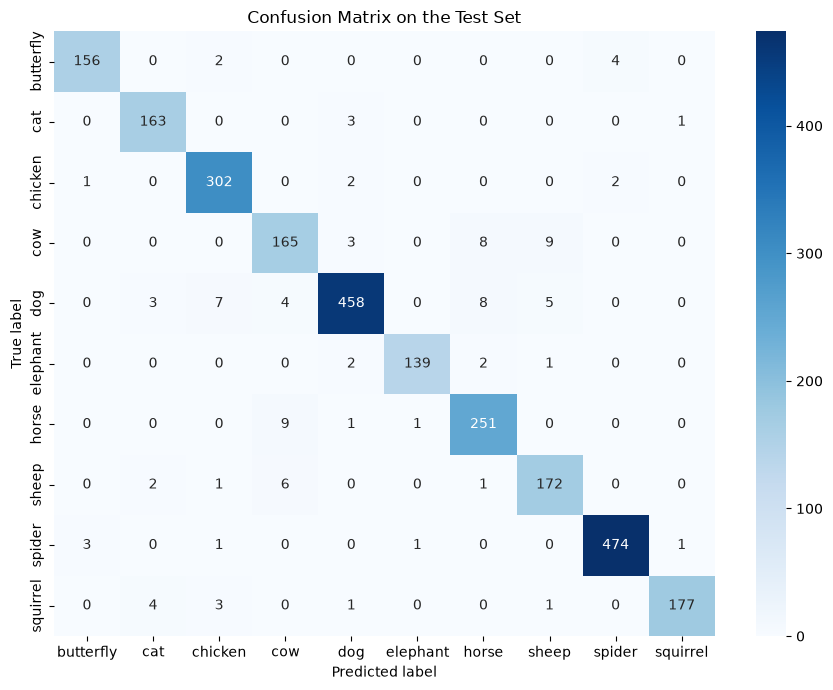

In [17]:
plt.figure(figsize=(9, 7))
sns.heatmap(confusion_matrix(y_true, y_pred), annot=True, fmt="d", cmap="Blues",
            xticklabels=CLASS_NAMES, yticklabels=CLASS_NAMES)
plt.title("Confusion Matrix on the Test Set")
plt.xlabel("Predicted label")
plt.ylabel("True label")
plt.tight_layout()
plt.show()

## Model Conversion
The model is saved in three formats: **SavedModel**, **TF-Lite**, and **TFJS**.

In [18]:
# 1. SavedModel
SAVED_MODEL_DIR = "saved_model"
model.export(SAVED_MODEL_DIR, verbose=False)
print(sorted(os.listdir(SAVED_MODEL_DIR)))

INFO:tensorflow:Assets written to: saved_model/assets


INFO:tensorflow:Assets written to: saved_model/assets


['assets', 'fingerprint.pb', 'saved_model.pb', 'variables']


In [19]:
# 2. TF-Lite (with label.txt)
os.makedirs("tflite", exist_ok=True)

converter = tf.lite.TFLiteConverter.from_saved_model(SAVED_MODEL_DIR)
tflite_model = converter.convert()

with open("tflite/model.tflite", "wb") as f:
    f.write(tflite_model)

with open("tflite/label.txt", "w") as f:
    f.write("\n".join(CLASS_NAMES))

print(sorted(os.listdir("tflite")), f"- model size: {len(tflite_model) / 1e6:.2f} MB")

['label.txt', 'model.tflite'] - model size: 14.86 MB


In [20]:
# 3. TensorFlow.js
tfjs.converters.convert_tf_saved_model(SAVED_MODEL_DIR, "tfjs_model")
print(sorted(os.listdir("tfjs_model")))

['group1-shard1of4.bin', 'group1-shard2of4.bin', 'group1-shard3of4.bin', 'group1-shard4of4.bin', 'model.json']


## Inference
Inference is done with the saved **TF-Lite model**.
An image only needs to be read and resized to 224x224; normalization is already part of the model.

In [21]:
interpreter = tf.lite.Interpreter(model_path="tflite/model.tflite")
interpreter.allocate_tensors()
input_details = interpreter.get_input_details()[0]
output_details = interpreter.get_output_details()[0]

with open("tflite/label.txt") as f:
    tflite_labels = f.read().splitlines()

print("Input :", input_details["shape"], input_details["dtype"])
print("Output:", output_details["shape"], output_details["dtype"])


def predict_tflite(image_path):
    """Predict a single image with the TF-Lite model and return (label, confidence)."""
    image, _ = load_image(image_path, 0)
    interpreter.set_tensor(input_details["index"], tf.expand_dims(image, 0).numpy())
    interpreter.invoke()
    probabilities = interpreter.get_tensor(output_details["index"])[0]
    return tflite_labels[int(np.argmax(probabilities))], float(np.max(probabilities))

Input : [  1 224 224   3] <class 'numpy.float32'>
Output: [ 1 10] <class 'numpy.float32'>


/Library/Frameworks/Python.framework/Versions/3.13/lib/python3.13/site-packages/tensorflow/lite/python/interpreter.py:457: UserWarning:     Warning: tf.lite.Interpreter is deprecated and is scheduled for deletion in
    TF 2.20. Please use the LiteRT interpreter from the ai_edge_litert package.
    See the [migration guide](https://ai.google.dev/edge/litert/migration)
    for details.
    
  warnings.warn(_INTERPRETER_DELETION_WARNING)
INFO: Created TensorFlow Lite XNNPACK delegate for CPU.


true: dog        predicted: dog        (100.00%)
true: sheep      predicted: sheep      (100.00%)
true: dog        predicted: dog        (99.92%)
true: horse      predicted: horse      (99.99%)
true: dog        predicted: dog        (100.00%)


true: horse      predicted: horse      (98.84%)
true: horse      predicted: horse      (100.00%)


true: chicken    predicted: chicken    (100.00%)


true: cat        predicted: cat        (99.99%)
true: elephant   predicted: elephant   (100.00%)


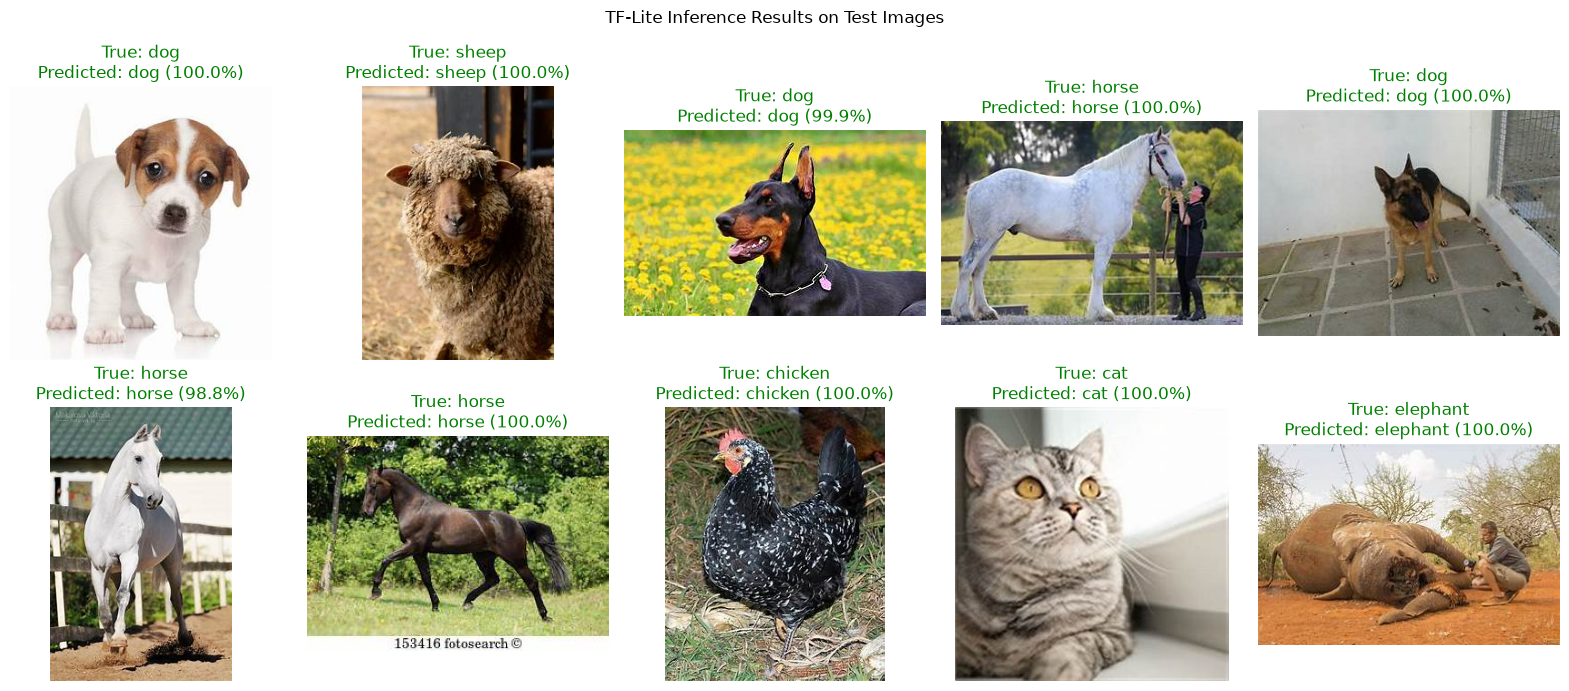

In [22]:
samples = test_df.sample(10, random_state=7)

plt.figure(figsize=(16, 7))
for i, row in enumerate(samples.itertuples()):
    predicted, confidence = predict_tflite(row.path)
    plt.subplot(2, 5, i + 1)
    plt.imshow(Image.open(row.path).convert("RGB"))
    plt.title(f"True: {row.label}\nPredicted: {predicted} ({confidence:.1%})",
              color="green" if predicted == row.label else "red")
    plt.axis("off")
    print(f"true: {row.label:10s} predicted: {predicted:10s} ({confidence:.2%})")
plt.suptitle("TF-Lite Inference Results on Test Images")
plt.tight_layout()
plt.show()

In [23]:
# TF-Lite model accuracy on 500 random test images
subset = test_df.sample(500, random_state=SEED)
correct = sum(predict_tflite(row.path)[0] == row.label for row in subset.itertuples())
print(f"TF-Lite accuracy on {len(subset)} test images: {correct / len(subset):.4f}")

TF-Lite accuracy on 500 test images: 0.9720
